# 🌳 Notebook 2: Plant Viability Detection (Dead vs. Alive)

## 1. Scientific Objective & Physiological Rationale
Distinguish between living plants (active resting potentials & physiological responses) and dead tissue (flatline zero electrical potential).
All plots are automatically saved to `plot/02_viability_dead_vs_alive_rf/`.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score, accuracy_score
from sklearn.decomposition import PCA

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

NOTEBOOK_NAME = "02_viability_dead_vs_alive_rf"
if os.path.basename(os.getcwd()) == "notebook":
    PLOT_DIR = os.path.join("..", "plot", NOTEBOOK_NAME)
    DATA_PATH = "plant_time_series_features.csv"
else:
    PLOT_DIR = os.path.join("plot", NOTEBOOK_NAME)
    DATA_PATH = os.path.join("notebook", "plant_time_series_features.csv") if os.path.exists(os.path.join("notebook", "plant_time_series_features.csv")) else "plant_time_series_features.csv"

os.makedirs(PLOT_DIR, exist_ok=True)
print(f"Plots will be saved to: {os.path.abspath(PLOT_DIR)}")

df = pd.read_csv(DATA_PATH)
print("Class counts:")
print(df["is_alive"].value_counts().rename({1: "Alive", 0: "Dead"}))


Plots will be saved to: C:\Users\asim\projects\others\PLANT-EMOTION-DETECTION\plot\02_viability_dead_vs_alive_rf
Class counts:
is_alive
Alive    3499
Dead       30
Name: count, dtype: int64


## 2. Feature Matrix & Session-Grouped Split

In [2]:
feature_cols = [
    "mean", "std", "var", "min", "max", "range", "median", 
    "rms", "mad", "p25", "p75", "iqr", "zcr", "skew", "kurt", 
    "peak_count", "low_freq_power", "mid_freq_power", "high_freq_power", 
    "spectral_entropy", "dominant_freq"
]

X = df[feature_cols].values
y = df["is_alive"].values
groups = df["session_id"].values

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"X shape: {X.shape}, y shape: {y.shape}")


X shape: (3529, 21), y shape: (3529,)


## 3. Train Random Forest & HistGradientBoosting with Cross-Validation

In [3]:
rf_model = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42, n_jobs=-1)
oof_preds_rf = np.zeros(len(y))
oof_proba_rf = np.zeros(len(y))

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
    rf_model.fit(X[train_idx], y[train_idx])
    oof_proba_rf[test_idx] = rf_model.predict_proba(X[test_idx])[:, 1]
    oof_preds_rf[test_idx] = (oof_proba_rf[test_idx] >= 0.5).astype(int)

acc_rf = accuracy_score(y, oof_preds_rf)
print(f"Random Forest Session-Grouped Accuracy: {acc_rf*100:.2f}%\n")
print(classification_report(y, oof_preds_rf, target_names=["Dead", "Alive"]))


Random Forest Session-Grouped Accuracy: 100.00%

              precision    recall  f1-score   support

        Dead       1.00      1.00      1.00        30
       Alive       1.00      1.00      1.00      3499

    accuracy                           1.00      3529
   macro avg       1.00      1.00      1.00      3529
weighted avg       1.00      1.00      1.00      3529



## 4. Normalized Confusion Matrices

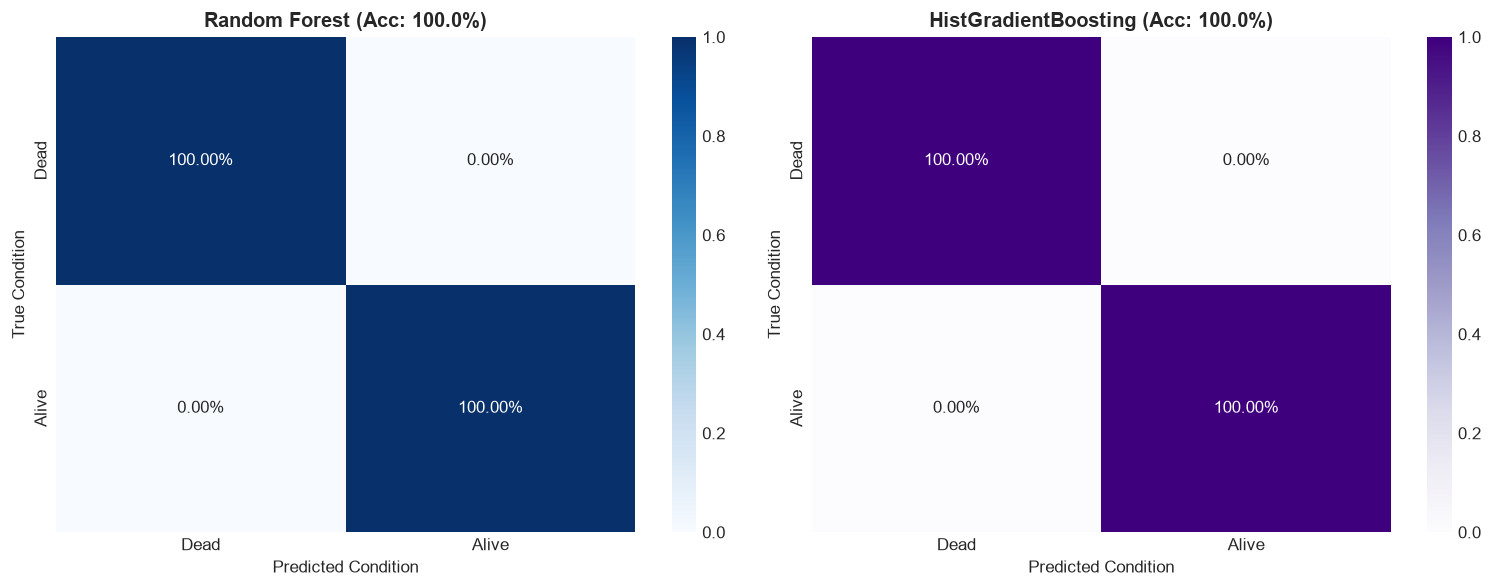

In [4]:
hgb_model = HistGradientBoostingClassifier(max_iter=100, random_state=42)
oof_proba_hgb = np.zeros(len(y))
oof_preds_hgb = np.zeros(len(y))

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
    hgb_model.fit(X[train_idx], y[train_idx])
    oof_proba_hgb[test_idx] = hgb_model.predict_proba(X[test_idx])[:, 1]
    oof_preds_hgb[test_idx] = (oof_proba_hgb[test_idx] >= 0.5).astype(int)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

cm_rf = confusion_matrix(y, oof_preds_rf, normalize='true')
sns.heatmap(cm_rf, annot=True, fmt=".2%", cmap="Blues", ax=ax1, xticklabels=["Dead", "Alive"], yticklabels=["Dead", "Alive"])
ax1.set_title(f"Random Forest (Acc: {acc_rf*100:.1f}%)", fontweight='bold')
ax1.set_ylabel("True Condition")
ax1.set_xlabel("Predicted Condition")

cm_hgb = confusion_matrix(y, oof_preds_hgb, normalize='true')
sns.heatmap(cm_hgb, annot=True, fmt=".2%", cmap="Purples", ax=ax2, xticklabels=["Dead", "Alive"], yticklabels=["Dead", "Alive"])
ax2.set_title(f"HistGradientBoosting (Acc: {accuracy_score(y, oof_preds_hgb)*100:.1f}%)", fontweight='bold')
ax2.set_ylabel("True Condition")
ax2.set_xlabel("Predicted Condition")

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "1_confusion_matrices.png"), dpi=300, bbox_inches='tight')
plt.show()


## 5. ROC-AUC and Precision-Recall Curves

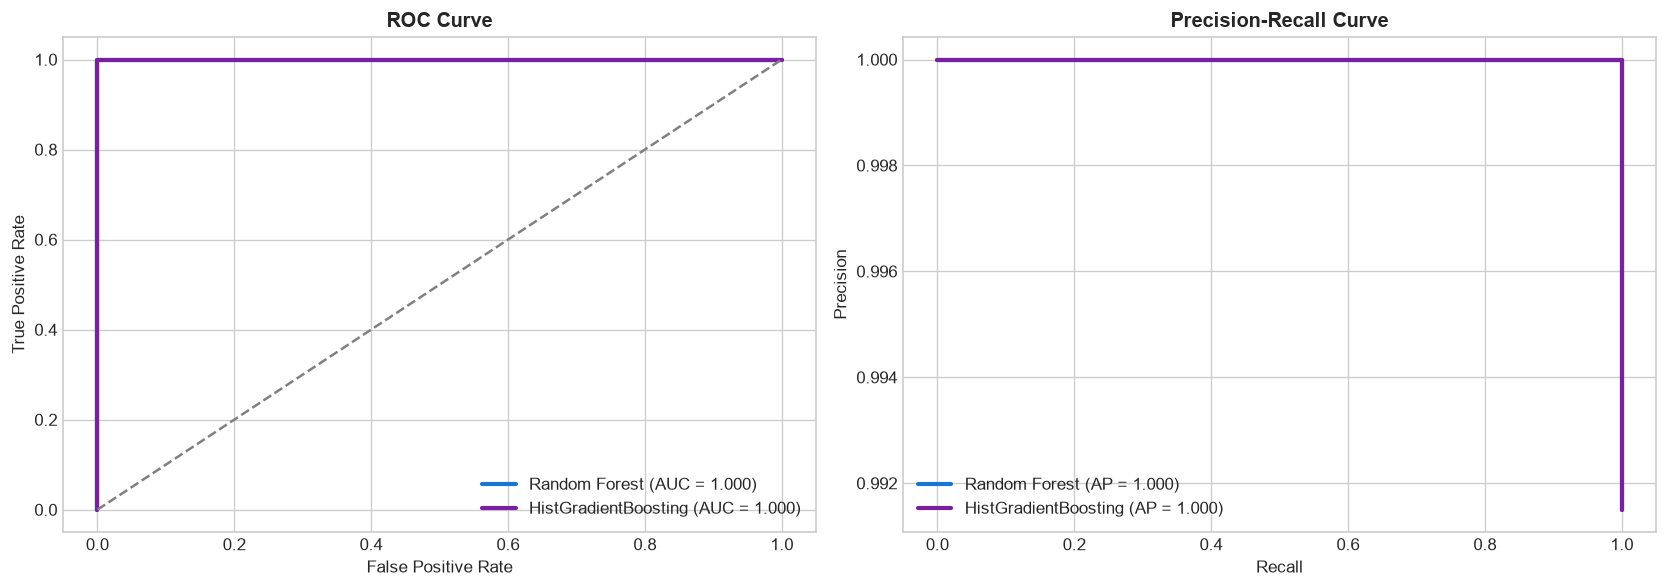

In [5]:
fpr_rf, tpr_rf, _ = roc_curve(y, oof_proba_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)
fpr_hgb, tpr_hgb, _ = roc_curve(y, oof_proba_hgb)
roc_auc_hgb = auc(fpr_hgb, tpr_hgb)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(fpr_rf, tpr_rf, color='#1976D2', lw=2.5, label=f'Random Forest (AUC = {roc_auc_rf:.3f})')
ax1.plot(fpr_hgb, tpr_hgb, color='#7B1FA2', lw=2.5, label=f'HistGradientBoosting (AUC = {roc_auc_hgb:.3f})')
ax1.plot([0, 1], [0, 1], color='gray', linestyle='--')
ax1.set_title("ROC Curve", fontweight='bold')
ax1.set_xlabel("False Positive Rate")
ax1.set_ylabel("True Positive Rate")
ax1.legend(loc="lower right")
ax1.grid(True)

pre_rf, rec_rf, _ = precision_recall_curve(y, oof_proba_rf)
ax2.plot(rec_rf, pre_rf, color='#1976D2', lw=2.5, label=f'Random Forest (AP = {average_precision_score(y, oof_proba_rf):.3f})')
pre_hgb, rec_hgb, _ = precision_recall_curve(y, oof_proba_hgb)
ax2.plot(rec_hgb, pre_hgb, color='#7B1FA2', lw=2.5, label=f'HistGradientBoosting (AP = {average_precision_score(y, oof_proba_hgb):.3f})')
ax2.set_title("Precision-Recall Curve", fontweight='bold')
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.legend(loc="lower left")
ax2.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "2_roc_pr_curves.png"), dpi=300, bbox_inches='tight')
plt.show()


## 6. Feature Importance Ranking

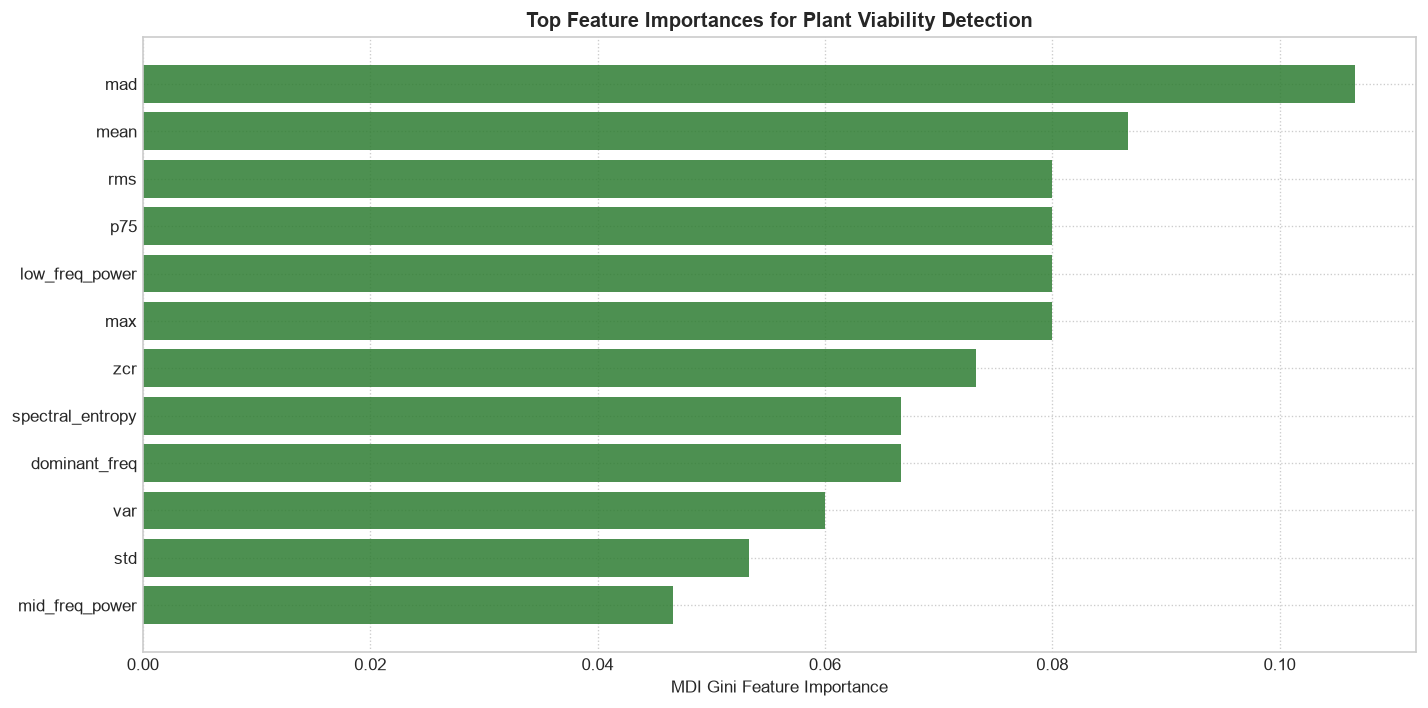

In [6]:
rf_model.fit(X, y)
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 6))
top_n = 12
plt.barh(range(top_n), importances[indices[:top_n]][::-1], color="#2E7D32", alpha=0.85, align="center")
plt.yticks(range(top_n), [feature_cols[i] for i in indices[:top_n]][::-1])
plt.xlabel("MDI Gini Feature Importance")
plt.title("Top Feature Importances for Plant Viability Detection", fontweight='bold')
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "3_feature_importances.png"), dpi=300, bbox_inches='tight')
plt.show()


## 7. PCA 2D Latent Space & Decision Boundary

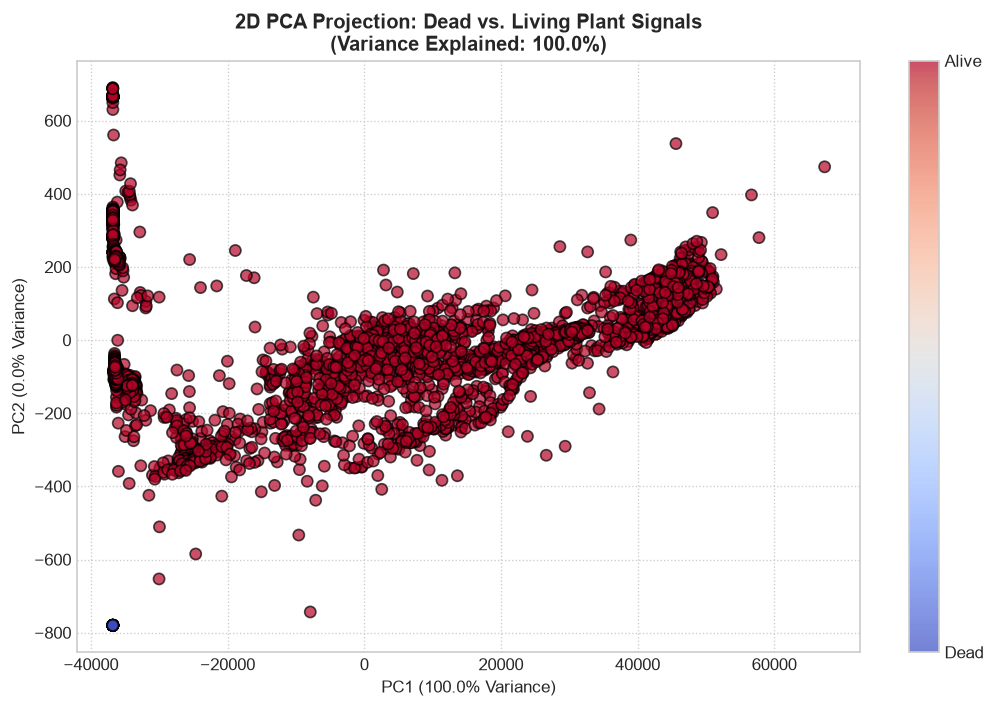

In [7]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm", alpha=0.7, edgecolors='k', s=45)
plt.title(f"2D PCA Projection: Dead vs. Living Plant Signals\n(Variance Explained: {pca.explained_variance_ratio_.sum()*100:.1f}%)", fontweight='bold')
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)")
cbar = plt.colorbar(scatter, ticks=[0, 1])
cbar.set_ticklabels(["Dead", "Alive"])
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "4_pca_latent_space.png"), dpi=300, bbox_inches='tight')
plt.show()
